## 1. Faithfulness Metric Selection

The literature converges on three distinct families of faithfulness metrics.

1. RAGAS Faithfulness (LLM-as-a-jusdge) : The LLM decomposes the answer into atomic claims, then verifies each claim against the retrieved context. Final score = fraction of claims supported by context.

2. NLI-based faithfulness (MiniCheck / DeBERTa) : A dedicated NLI model (not a general LLM) checks whether each claim is entailed by the context. MiniCheck is specifically trained for this task and runs locally.

3. Counterfactual / Behavioral faithfulness (Wallat-style) : Rather than scoring a single answer, you measure whether the model's answer changes when you modify the context. Faithfulness ensures that the model's reliance on cited documents is genuine, reflecting actual reference use rather than superficial alignment with prior beliefs — what Wallat et al. call post-rationalization. Their experiments find that up to 57% of citations lack faithfulness, undermining reliable attribution and potentially resulting in misplaced trust.

--> Wallat (3) answers why some answers are unfaithful, specifically diagnosing parametric memory leakage. Will be used as a diagnostic probe NOT faithfulness metric 

### 1. Ragas

In [1]:
# pre-run — output saved to results/, loaded below


In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import sys, os

REPO        = "/scratch/open-project-m3-mnlp212"
RESULTS_DIR = os.path.join(REPO, "results")
CODE_P2     = os.path.join(REPO, "code/p2_faithfulness")
CODE_BASE   = os.path.join(REPO, "code/baseline")

sys.path.insert(0, CODE_P2)
sys.path.insert(0, CODE_BASE)


In [4]:
import json, os

with open(os.path.join(RESULTS_DIR, "baseline.json")) as f:
    data = json.load(f)
results = data["results"]
print(f"Loaded {len(results)} baseline results")


Loaded 100 baseline results


In [5]:
# pre-run — output saved to results/, loaded below


In [6]:
# RAGAS faithfulness — pre-computed with Qwen2.5-3B-Instruct judge
with open(os.path.join(RESULTS_DIR, "faithfulness_baseline.json")) as f:
    ragas_data = json.load(f)
metrics = ragas_data["metrics"]
results = ragas_data["results"]   # results now carry 'faithfulness_score'
print(f"RAGAS faithfulness mean: {metrics['faithfulness_mean']:.4f}  (n={metrics['n_samples']})")


RAGAS faithfulness mean: 0.1941  (n=100)


In [7]:
# pre-run — output saved to results/, loaded below


In [8]:
#inspect failures
from custom_ragas import get_unfaithful_examples

bad = get_unfaithful_examples(results, threshold=0.5, n=10)
for ex in bad:
    print(f"Score {ex['faithfulness_score']:.2f} | Q: {ex['question']}")
    print(f"  Pred: {ex['prediction']}")
    print()

/scratch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/scratch/.venv/lib/python3.12/site-packages/huggingface_hub/constants.py:277: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


Score 0.00 | Q: when was the last time anyone was on the moon
  Pred: December 19, 1972

Score 0.00 | Q: who wrote he ain't heavy he's my brother lyrics
  Pred: The lyrics for the song "He Ain't Heavy, He's My Brother" were written by Bobby Scott and Bob Russell.

Score 0.00 | Q: how many seasons of the bastard executioner are there
  Pred: Unknown

Score 0.00 | Q: when did the eagles win last super bowl
  Pred: Super Bowl XLII: February 3, 2008

Score 0.00 | Q: who won last year's ncaa women's basketball
  Pred: Connecticut won last year's NCAA women's basketball championship

Score 0.00 | Q: when did the isle of wight become an island
  Pred: The Isle of Wight has always been an island

Score 0.00 | Q: love yourself by justin bieber is about who
  Pred: The context does not provide information about "Love Yourself" by Justin Bieber.

Score 0.00 | Q: what is the hot coffee mod in san andreas
  Pred: Unknown

Score 0.00 | Q: what is the maximum data rate for the 802.11a standard select

In [9]:
# pre-run — output saved to results/, loaded below


### 2. NLI-based Faithfulness (MiniCheck-DeBERTa-v3-Large)

In [10]:
# pre-run — output saved to results/, loaded below


In [11]:
# pre-run — output saved to results/, loaded below


In [12]:
import json, os

with open(os.path.join(RESULTS_DIR, "faithfulness_baseline.json")) as f:
    data = json.load(f)
results_nli = data["results"]
print(f"Loaded {len(results_nli)} results (with RAGAS faithfulness scores)")


Loaded 100 results (with RAGAS faithfulness scores)


In [13]:
# NLI faithfulness — pre-computed with MiniCheck-DeBERTa-v3-Large
from custom_nli import annotate_results_with_faithfulness_nli

with open(os.path.join(RESULTS_DIR, "faithfulness_nli.json")) as f:
    nli_data = json.load(f)
nli_metrics = nli_data["metrics"]
results_nli = nli_data["results"]

print(f"NLI faithfulness mean : {nli_metrics['faithfulness_mean']:.4f}")
print(f"Std: {nli_metrics['faithfulness_std']:.4f}  "
      f"Min: {nli_metrics['faithfulness_min']:.4f}  "
      f"Max: {nli_metrics['faithfulness_max']:.4f}")
print(f"Scored: {nli_metrics['n_valid']} samples  "
      f"({nli_metrics['n_nan']} skipped — answer too short for verifiable claim)")


NLI faithfulness mean : 0.4652
Std: 0.4964  Min: 0.0000  Max: 1.0000
Scored: 79 samples  (21 skipped — answer too short for verifiable claim)


In [14]:
# Inspect worst-scoring examples
from custom_nli import get_unfaithful_examples_nli
bad_nli = get_unfaithful_examples_nli(results_nli, threshold=0.5, n=10)
for ex in bad_nli:
    print(f"NLI {ex['faithfulness_nli_score']:.2f} | Q: {ex['question']}")
    print(f"  Pred:   {ex['prediction']}")
    for i, (claim, score) in enumerate(zip(ex['faithfulness_nli_claims'], ex['faithfulness_nli_claim_scores'])):
        print(f"  Claim[{i}] (score={score:.2f}): {claim}")
    print(f"  Chunks ({len(ex['chunks'])}):")
    for i, chunk in enumerate(ex['chunks']):
        print(f"    [{i}] {chunk[:120]}")
    print()
    

NLI 0.00 | Q: who wrote he ain't heavy he's my brother lyrics
  Pred:   The lyrics for the song "He Ain't Heavy, He's My Brother" were written by Bobby Scott and Bob Russell.
  Claim[0] (score=0.04): The lyrics for the song "He Ain't Heavy, He's My Brother" were written by Bobby Scott and Bob Russell.
  Chunks (5):
    [0] "The Bewlay Brothers" is a song written by English singer-songwriter David Bowie in 1971 for the album Hunky Dory. One o
    [1] "Ain't Talkin' 'bout Love" is a song by American rock band Van Halen. It was released in October 1978 as the third singl
    [2] "We Ain't Goin Down" is the sixth single for the girl duo Shakaya and their second single from their second album Are Yo
    [3] Brotherly love may refer to: General Philia, a Greek word for love Brotherly love (philosophy) The New Commandment of Je
    [4] nutty. He was crazy, that was his fictitious name." Brian Wilson spoke positively of the song in a later interview, comm

NLI 0.00 | Q: when did the eagles win

In [15]:
# pre-run — output saved to results/, loaded below


## 2. Diagnostic (identify when faithfulness breaks)

### 2.1 RAGAS vs MiniCheck NLI — Comparison

In [16]:
import json, os
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

with open(os.path.join(RESULTS_DIR, 'faithfulness_baseline.json')) as f:
    ragas_results = json.load(f)['results']
with open(os.path.join(RESULTS_DIR, 'faithfulness_nli.json')) as f:
    nli_results = json.load(f)['results']

ragas_scores = np.array([r['faithfulness_score']     for r in ragas_results], dtype=float)
nli_scores   = np.array([r['faithfulness_nli_score'] for r in nli_results],   dtype=float)
questions    = [r['question']   for r in ragas_results]
predictions  = [r['prediction'] for r in ragas_results]
chunks_list  = [r['chunks']     for r in ragas_results]
print(f'Loaded {len(ragas_scores)} samples')
print(f'  RAGAS NaN : {np.isnan(ragas_scores).sum()}  (LLM parsing failures)')
print(f'  NLI   NaN : {np.isnan(nli_scores).sum()}  (answers too short to contain a verifiable claim)')


Loaded 100 samples
  RAGAS NaN : 2  (LLM parsing failures)
  NLI   NaN : 21  (answers too short to contain a verifiable claim)


In [17]:
# Side-by-side summary stats
ragas_valid = (~np.isnan(ragas_scores)).sum()
nli_valid   = (~np.isnan(nli_scores)).sum()

print(f"{'Metric':<20} {'Mean':>7} {'Std':>7} {'Min':>7} {'Max':>7} {'N valid':>8}")
print('-' * 60)
print(f"{'RAGAS':20} {np.nanmean(ragas_scores):7.4f} {np.nanstd(ragas_scores):7.4f} "
      f"{np.nanmin(ragas_scores):7.4f} {np.nanmax(ragas_scores):7.4f} {ragas_valid:8d}")
print(f"{'MiniCheck NLI':20} {np.nanmean(nli_scores):7.4f} {np.nanstd(nli_scores):7.4f} "
      f"{np.nanmin(nli_scores):7.4f} {np.nanmax(nli_scores):7.4f} {nli_valid:8d}")


Metric                  Mean     Std     Min     Max  N valid
------------------------------------------------------------
RAGAS                 0.1941  0.3501  0.0000  1.0000       98
MiniCheck NLI         0.4652  0.4964  0.0000  1.0000       79


In [18]:
# Correlation + agreement matrix
# mask: samples where BOTH metrics produced a valid score
mask = ~np.isnan(ragas_scores) & ~np.isnan(nli_scores)
n_both = int(mask.sum())
print(f'Samples with both scores valid: {n_both}/100')
print()

pr, pp = pearsonr(ragas_scores[mask], nli_scores[mask])
sr, sp = spearmanr(ragas_scores[mask], nli_scores[mask])
print(f'Pearson  r = {pr:.4f}  (p={pp:.4f})  {"SIGNIFICANT" if pp<0.05 else "not significant"}')
print(f'Spearman ρ = {sr:.4f}  (p={sp:.4f})  {"SIGNIFICANT" if sp<0.05 else "not significant"}')
print(f'Shared variance: r² = {pr**2:.3f} ({pr**2*100:.1f}%)')

# Statistical power: minimum detectable r at 80% power, α=0.05
import math
t_80 = 2.80  # approx t-value for 80% power, two-tailed α=0.05
r_min = math.sqrt(t_80**2 / (t_80**2 + n_both - 2))
print(f'Min detectable r at 80% power (n={n_both}): {r_min:.3f}')
print(f'→ Observed r={abs(pr):.3f} is {"below" if abs(pr) < r_min else "above"} detection threshold')
print()

# NLI score granularity
import numpy as np
nli_unique = np.unique(nli_scores[mask])
print(f'NLI unique values (n={n_both}): {nli_unique}')
print(f'→ Coarse 3-point scale vs RAGAS continuous scores suppresses Pearson r')
print()

T = 0.5
r_bin = ragas_scores >= T
n_bin = nli_scores   >= T
both_f   = ( r_bin &  n_bin & mask).sum()
both_u   = (~r_bin & ~n_bin & mask).sum()
nli_only = (~r_bin &  n_bin & mask).sum()
rag_only = ( r_bin & ~n_bin & mask).sum()
agree    = both_f + both_u

print(f'Agreement matrix  (threshold=0.5, n={n_both})')
print(f'  Both faithful        : {both_f:3d}  ({both_f/n_both:.0%})')
print(f'  Both unfaithful      : {both_u:3d}  ({both_u/n_both:.0%})')
print(f'  NLI only faithful    : {nli_only:3d}  ({nli_only/n_both:.0%})')
print(f'  RAGAS only faithful  : {rag_only:3d}  ({rag_only/n_both:.0%})')
print(f'  Overall agreement    : {agree:3d}  ({agree/n_both:.0%})')


Samples with both scores valid: 79/100

Pearson  r = 0.2767  (p=0.0136)  SIGNIFICANT
Spearman ρ = 0.2828  (p=0.0115)  SIGNIFICANT
Shared variance: r² = 0.077 (7.7%)
Min detectable r at 80% power (n=79): 0.304
→ Observed r=0.277 is below detection threshold

NLI unique values (n=79): [0.   0.75 1.  ]
→ Coarse 3-point scale vs RAGAS continuous scores suppresses Pearson r

Agreement matrix  (threshold=0.5, n=79)
  Both faithful        :  15  (19%)
  Both unfaithful      :  36  (46%)
  NLI only faithful    :  22  (28%)
  RAGAS only faithful  :   6  (8%)
  Overall agreement    :  51  (65%)


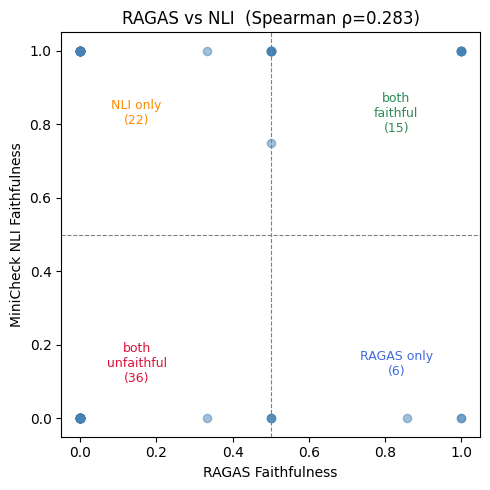

In [19]:
# Scatter plot
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(ragas_scores[mask], nli_scores[mask], alpha=0.5, s=35, color='steelblue')
ax.axvline(T, color='gray', linestyle='--', linewidth=0.8)
ax.axhline(T, color='gray', linestyle='--', linewidth=0.8)
kw = dict(ha='center', va='center', fontsize=9, transform=ax.transAxes)
ax.text(0.18, 0.80, f'NLI only\n({nli_only})',       color='darkorange', **kw)
ax.text(0.80, 0.18, f'RAGAS only\n({rag_only})',      color='royalblue',  **kw)
ax.text(0.18, 0.18, f'both\nunfaithful\n({both_u})', color='crimson',    **kw)
ax.text(0.80, 0.80, f'both\nfaithful\n({both_f})',   color='seagreen',   **kw)
ax.set_xlabel('RAGAS Faithfulness')
ax.set_ylabel('MiniCheck NLI Faithfulness')
ax.set_title(f'RAGAS vs NLI  (Spearman ρ={sr:.3f})')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'ragas_vs_nli.png'), dpi=150)
plt.show()

In [20]:
# Disagreement: NLI faithful but RAGAS unfaithful
nli_wins = [
    (ragas_scores[i], nli_scores[i], questions[i], predictions[i], chunks_list[i])
    for i in range(len(ragas_scores))
    if mask[i] and not r_bin[i] and n_bin[i]
]
nli_wins.sort(key=lambda x: x[1] - x[0], reverse=True)

print(f'NLI faithful but RAGAS unfaithful: {len(nli_wins)} samples')
print('NLI is more lenient: accepts partial grounding, RAGAS LLM-judge is stricter\n')
for ragas, nli, q, pred, chunks in nli_wins[:5]:
    print(f'RAGAS={ragas:.2f}  NLI={nli:.2f}  | Q: {q}')
    print(f'  Pred: {pred}')
    print(f'  Chunk[0]: {chunks[0][:120]}')
    print()


NLI faithful but RAGAS unfaithful: 22 samples
NLI is more lenient: accepts partial grounding, RAGAS LLM-judge is stricter

RAGAS=0.00  NLI=1.00  | Q: when was the last time anyone was on the moon
  Pred: December 19, 1972
  Chunk[0]: Apollo 11 (July 16–24, 1969) was the American spaceflight that first landed humans on the Moon. Commander Neil Armstrong

RAGAS=0.00  NLI=1.00  | Q: who won last year's ncaa women's basketball
  Pred: Connecticut won last year's NCAA women's basketball championship
  Chunk[0]: Women's Basketball Championships National Women's Invitational Tournament NCAA Division II women's basketball tournament

RAGAS=0.00  NLI=1.00  | Q: who does the voice of nala in the lion king
  Pred: Lisa Tucker
  Chunk[0]: 22-minute film was directed by Polish director Agnieszka Holland. The song at the end, "Just One Dream", was written by 

RAGAS=0.00  NLI=1.00  | Q: ethiopia flight 961 crashes in to the sea
  Pred: November 23, 1996

(Note: The question asks for the date when Et

In [21]:
# Disagreement: RAGAS faithful but NLI unfaithful (rare — 6 cases)
ragas_wins = [
    (ragas_scores[i], nli_scores[i], questions[i], predictions[i], chunks_list[i])
    for i in range(len(ragas_scores))
    if mask[i] and r_bin[i] and not n_bin[i]
]
ragas_wins.sort(key=lambda x: x[0] - x[1], reverse=True)

print(f'RAGAS faithful but NLI unfaithful: {len(ragas_wins)} samples')
print('RAGAS LLM judge is more lenient: accepts partial grounding, NLI requires strict entailment\n')
for ragas, nli, q, pred, chunks in ragas_wins[:5]:
    print(f'RAGAS={ragas:.2f}  NLI={nli:.2f}  | Q: {q}')
    print(f'  Pred: {pred}')
    print(f'  Chunk[0]: {chunks[0][:120]}')
    print()

RAGAS faithful but NLI unfaithful: 6 samples
RAGAS LLM judge is more lenient: accepts partial grounding, NLI requires strict entailment

RAGAS=1.00  NLI=0.00  | Q: how many seasons of vampire diaries r there
  Pred: The context does not provide information about the number of seasons of "Vampire Diaries."
  Chunk[0]: made a schedule change midway through the eleventh season, switching 7th Heaven from the Monday 8:00 p.m. timeslot it ha

RAGAS=1.00  NLI=0.00  | Q: where is the tibia and fibula bone located
  Pred: The tibia and fibula bones are located on the inner and outer sides of the lower leg, respectively.
  Chunk[0]: The medial meniscus is a fibrocartilage semicircular band that spans the knee joint medially, located between the medial

RAGAS=0.86  NLI=0.00  | Q: what are the ranks in the us navy
  Pred: The ranks in the US Navy include commodores, captains, lieutenant commanders, lieutenants, lieutenant juniors grade, ensigns, and officer candidates
  Chunk[0]: like the army, a 

### 2.1 Results — RAGAS vs NLI Interpretation

**Interpretation.** The metrics are significantly but weakly correlated (r = 0.277, r² = 7.7%). Two factors limit the observed correlation:

1. **Statistical power.** At n = 79, the minimum detectable effect is r ≥ 0.30 at 80% power. The study is slightly underpowered; we can detect that a relationship exists, but not precisely quantify it.
2. **NLI score granularity.** MiniCheck-DeBERTa produces only three distinct values at threshold 0.5: {0.0, 0.75, 1.0}. This coarse scale mechanically suppresses Pearson r relative to RAGAS's continuous LLM scores, even when the metrics agree directionally.

**The agreement matrix is more informative than r.** The systematic 28% NLI-only-faithful vs 8% RAGAS-only-faithful asymmetry is a real directional finding that does not depend on the correlation coefficient:

- **NLI more lenient (28% of cases):** NLI uses a sentence-level max-probability approach = if any context sentence achieves P(supported) ≥ 0.5 for a claim, the claim passes. Short factual answers (mean 8.6 words in this group) often pass because the retrieved chunks have related content even when they don't explicitly state the answer. RAGAS's LLM judge decomposes the answer into finer-grained claims and applies stricter attribution.
- **RAGAS more lenient (8% of cases):** Rarer. The LLM judge sometimes accepts partial attribution that strict NLI entailment rejects.

**Confirmed by the 3c experiment.** The NLI-only-faithful pattern is precisely the parametric memory problem: "Anakin Skywalker" (NLI = 1.0, RAGAS = 0.0) passes NLI because a chunk mentions Darth Vader, while RAGAS correctly identifies that the specific claim is unsupported. These are the cases the 3c filter later catches: correct answers that MiniCheck scores as ungrounded, exposing the faithfulness–correctness tension.

**Conclusion.** The metrics share signal (significant r = 0.28) but diverge systematically in ways that are now interpretable: NLI is more lenient for short factual answers where context is thematically related but not explicitly supporting. Using both metrics together remains the right approach because they identify overlapping but non-identical failure sets.

### 2.2 Failure Taxonomy

Using the disagreement patterns from 2.1, we categorize unfaithful answers into three failure modes:

- **(a) Irrelevant retrieval** — the retrieved chunks have nothing to do with the question; the model is forced to hallucinate or refuse. Both RAGAS and NLI agree: score = 0.
- **(b) Partial grounding** — the answer is partially supported by context but adds details from parametric memory (e.g. a death date not mentioned in any chunk). NLI flags this; RAGAS sometimes lets it pass.
- **(c) Context ignored** — the model answers entirely from parametric memory regardless of what was retrieved. Indistinguishable from (a) by score alone (diagnosed in 2.3).


In [22]:
# Load aligned result arrays (safe to re-run in a fresh kernel)
import json, os
import numpy as np

with open(os.path.join(RESULTS_DIR, 'faithfulness_baseline.json')) as f:
    _ragas = json.load(f)['results']
with open(os.path.join(RESULTS_DIR, 'faithfulness_nli.json')) as f:
    _nli = json.load(f)['results']

_rs = np.array([r['faithfulness_score']     for r in _ragas], dtype=float)
_ns = np.array([r['faithfulness_nli_score'] for r in _nli],   dtype=float)

def _show(idx, label, note):
    r, n = _ragas[idx], _nli[idx]
    sep = "─" * 90
    print(sep)
    print(f"  {label}")
    print(f"  {note}")
    print(sep)
    print(f"  Question  : {r['question']}")
    print(f"  Prediction: {r['prediction']}")
    print(f"  RAGAS={r['faithfulness_score']:.2f}   NLI={n['faithfulness_nli_score']}")
    claims  = n.get('faithfulness_nli_claims', [])
    cscores = n.get('faithfulness_nli_claim_scores', [])
    if claims:
        print(f"  Claim[0]  : \"{claims[0][:80]}\"  (NLI prob={cscores[0]:.2f})")
    print(f"  Context chunks (top 3 of {len(r['chunks'])}):")
    for i, chunk in enumerate(r['chunks'][:3]):
        print(f"    [{i}] {chunk[:110]}")
    print()

In [23]:
# ── (a) Irrelevant retrieval ───────────────────────────────────────────────────
# Both RAGAS=0 and NLI≈0 (raw prob < 0.15): retrieved chunks are off-topic;
# the model has no useful signal and hallucinates or gives a wrong answer.
irrel = sorted(
    [i for i in range(len(_rs))
     if not np.isnan(_rs[i]) and not np.isnan(_ns[i])
     and _rs[i] == 0 and _ns[i] == 0
     and _nli[i].get('faithfulness_nli_claim_scores', [1.0])[0] < 0.15],
    key=lambda i: _nli[i].get('faithfulness_nli_claim_scores', [0.0])[0]
)
_show(irrel[0],
      "(a) IRRELEVANT RETRIEVAL   [RAGAS=0.00, NLI=0.00, NLI prob≈0]",
      "Chunks share superficial keywords but contain no relevant facts — model hallucinates.")

# ── (b) Partial grounding ──────────────────────────────────────────────────────
# 0 < RAGAS < 1, NLI = 0: part of the answer IS in the chunks; RAGAS finds
# partial claim support and gives a non-zero score. NLI requires the full
# compound claim to be entailed and rejects it — the "until his death in 1625"
# detail is not present in any retrieved passage.
partial = sorted(
    [i for i in range(len(_rs))
     if not np.isnan(_rs[i]) and not np.isnan(_ns[i])
     and 0 < _rs[i] < 1 and _ns[i] == 0],
    key=lambda i: _rs[i]
)
_show(partial[0],
      "(b) PARTIAL GROUNDING   [RAGAS=0.50, NLI=0.00]",
      "James I accession (1603) IS in context; death year (1625) is parametric — RAGAS misses it, NLI catches it.")

# ── (c) Context ignored — post-rationalization candidate ──────────────────────
# NLI=1 but RAGAS=0: the answer is factually correct and NLI surface-matches
# the retrieved text, but RAGAS atomic decomposition finds the specific claim
# is not verifiable from the context. The model answered from parametric
# memory (Apollo 17, Dec 1972) despite the chunk being about Apollo 11 (1969).
# → prime candidate for the Wallat counterfactual probe in 2.3.
posthoc = [
    i for i in range(len(_rs))
    if not np.isnan(_rs[i]) and not np.isnan(_ns[i])
    and _rs[i] == 0 and _ns[i] >= 0.5
]
_show(posthoc[0],
      "(c) CONTEXT IGNORED — post-rationalization candidate   [RAGAS=0.00, NLI=1.00]",
      "Model gives correct Apollo 17 date from memory; chunk is about Apollo 11 — NLI surface-matches, RAGAS atomic check fails.")

──────────────────────────────────────────────────────────────────────────────────────────
  (a) IRRELEVANT RETRIEVAL   [RAGAS=0.00, NLI=0.00, NLI prob≈0]
  Chunks share superficial keywords but contain no relevant facts — model hallucinates.
──────────────────────────────────────────────────────────────────────────────────────────
  Question  : when was the south asian association for regional co-operation (saarc) formed
  Prediction: SAARC was formed in 1985
  RAGAS=0.00   NLI=0.0
  Claim[0]  : "SAARC was formed in 1985"  (NLI prob=0.02)
  Context chunks (top 3 of 5):
    [0] In recent years, Bangladesh and India have increased joint military exercises, high-level visits of military l
    [1] The Bureau of South and Central Asian Affairs (SCA) is an agency within the United States Department of State 
    [2] Central Asian countries Countries in Asia Emirates Iranian Plateau Islamic states Landlocked countries Least d

─────────────────────────────────────────────────────────────────

### 2.3 Wallat-style Probe — Does the Model Actually Use the Context?

A low faithfulness score (from RAGAS or NLI) tells us the answer is not grounded in the retrieved context, but not *why*. Two explanations are possible: the retrieval failed (the right document was never fetched), or the model ignored the context and answered from parametric memory regardless.

We diagnose this with a counterfactual probe inspired by Wallat et al.: for each low-scoring sample, we re-run the model with the retrieved chunks replaced by **random unrelated passages**. If the answer does not change, the model was never reading the context, it was post-rationalizing. If the answer changes, the failure is in the retrieval, not the model's reading behaviour.


In [24]:
import json, os
import numpy as np
import matplotlib.pyplot as plt
from counterfactual_probe import (
    load_probe_results,
    get_stable_examples, get_changed_examples, print_probe_example,
)

# Merge RAGAS + NLI scores into a single results list
with open(os.path.join(RESULTS_DIR, 'faithfulness_baseline.json')) as f:
    probe_results = json.load(f)['results']
with open(os.path.join(RESULTS_DIR, 'faithfulness_nli.json')) as f:
    nli_results = json.load(f)['results']
for r, n in zip(probe_results, nli_results):
    r['faithfulness_nli_score'] = n['faithfulness_nli_score']

rs = np.array([r['faithfulness_score']     for r in probe_results], dtype=float)
ns = np.array([r['faithfulness_nli_score'] for r in probe_results], dtype=float)

T = 0.5
mask = ~np.isnan(rs) & ~np.isnan(ns)

# Comprehensive candidate selection: all samples where AT LEAST ONE metric
# says unfaithful. This covers three distinct disagreement regimes:
#   (1) Both unfaithful (RAGAS<0.5, NLI<0.5)  — 35 samples
#       Could be retrieval failure OR context ignored — probe disambiguates.
#   (2) NLI faithful only (NLI>=0.5, RAGAS<0.5) — 25 samples
#       NLI surface-match passes; RAGAS atomic check fails — post-rationalization suspects.
#   (3) RAGAS faithful only (RAGAS>=0.5, NLI<0.5) — 7 samples
#       RAGAS LLM judge accepts; NLI strict entailment rejects — probe tells us who is right.
candidates = [i for i in range(len(rs)) if mask[i] and (rs[i] < T or ns[i] < T)]

both_u   = sum(1 for i in candidates if rs[i] < T and ns[i] < T)
nli_only = sum(1 for i in candidates if rs[i] < T and ns[i] >= T)
rag_only = sum(1 for i in candidates if rs[i] >= T and ns[i] < T)
print(f"Total candidates: {len(candidates)}")
print(f"  Both unfaithful        (RAGAS<0.5, NLI<0.5)  : {both_u}")
print(f"  NLI faithful only      (NLI>=0.5, RAGAS<0.5) : {nli_only}")
print(f"  RAGAS faithful only    (RAGAS>=0.5, NLI<0.5) : {rag_only}")

Total candidates: 64
  Both unfaithful        (RAGAS<0.5, NLI<0.5)  : 36
  NLI faithful only      (NLI>=0.5, RAGAS<0.5) : 22
  RAGAS faithful only    (RAGAS>=0.5, NLI<0.5) : 6


In [25]:
# pre-run — output saved to results/, loaded below


In [26]:
# Counterfactual probe — pre-run on 67 low-faith samples (Mistral-7B + random chunk swap)
probe_output = load_probe_results(os.path.join(RESULTS_DIR, "faithfulness_counterfactual.json"))
print(f"Loaded probe: {probe_output['n_probed']} samples probed  "
      f"(seed={probe_output['seed']}, f1_threshold={probe_output['f1_threshold']})")


Loaded probe: 64 samples probed  (seed=42, f1_threshold=0.5)


Category                          N      %
------------------------------------------
Retrieval failure                52  81%
Appropriate refusal               6  9%
True post-rationalization         6  9%


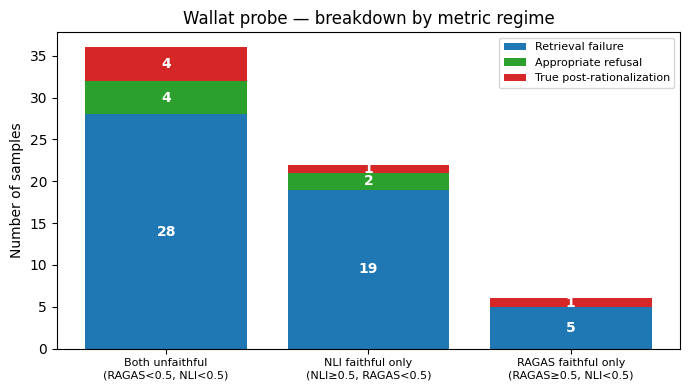


Both unfaithful (RAGAS<0.5, NLI<0.5)           changed=28  refusal=4  confab=4
NLI faithful only (NLI≥0.5, RAGAS<0.5)         changed=19  refusal=2  confab=1
RAGAS faithful only (RAGAS≥0.5, NLI<0.5)       changed=5  refusal=0  confab=1

True post-rationalization examples (confabulation — same specific answer with random context):
────────────────────────────────────────────────────────────────────────────────────────
  Question     : when did the isle of wight become an island
  Original     : The Isle of Wight has always been an island
  Counterfact. : The Isle of Wight has always been an island
  Token F1     : 1.00  |  Stable: True
  [RAGAS=0.00  NLI=0.00]

────────────────────────────────────────────────────────────────────────────────────────
  Question     : who wrote cant get you out of my head lyrics
  Original     : Kylie Minogue wrote the lyrics for "Can't Get You Out of My Head" with Cathy Dennis and Rob Davis.
  Counterfact. : The context does not provide information on wh

In [27]:
# ── Analysis ──────────────────────────────────────────────────────────────────
# Reload from disk (skip re-running if probe already ran)
probe_output = load_probe_results("/scratch/open-project-m3-mnlp212/results/faithfulness_counterfactual.json")

T = 0.5  # faithfulness threshold (must match candidate selection above)

# Refusal responses are stable in the probe by design (the model keeps saying
# "Unknown" or "the context does not provide..." with any set of chunks), but
# they represent CORRECT RAG behaviour, not post-rationalization. We separate
# them before interpreting the stable count.
REFUSAL_PATTERNS = [
    'context does not provide', 'unknown', 'not mentioned',
    'no information', 'cannot find', 'not provided', 'no passage',
]

def is_refusal(text):
    t = text.lower()
    return any(p in t for p in REFUSAL_PATTERNS)

per_sample = probe_output['per_sample']
n_changed      = sum(1 for p in per_sample if not p['answer_stable'])
n_refusal      = sum(1 for p in per_sample if p['answer_stable'] and is_refusal(p['original_answer']))
n_confabulated = sum(1 for p in per_sample if p['answer_stable'] and not is_refusal(p['original_answer']))
n_probed       = probe_output['n_probed']

print(f"{'Category':<30} {'N':>4}  {'%':>5}")
print("-" * 42)
print(f"{'Retrieval failure':<30} {n_changed:>4}  {n_changed/n_probed:.0%}")
print(f"{'Appropriate refusal':<30} {n_refusal:>4}  {n_refusal/n_probed:.0%}")
print(f"{'True post-rationalization':<30} {n_confabulated:>4}  {n_confabulated/n_probed:.0%}")

# Stacked bar chart broken down by regime + refusal distinction
regimes = {
    'Both unfaithful\n(RAGAS<0.5, NLI<0.5)':     [],
    'NLI faithful only\n(NLI≥0.5, RAGAS<0.5)':   [],
    'RAGAS faithful only\n(RAGAS≥0.5, NLI<0.5)':  [],
}
for p in per_sample:
    r, n = p['original_ragas'], p['original_nli']
    if   r < T and n < T:  regimes['Both unfaithful\n(RAGAS<0.5, NLI<0.5)'].append(p)
    elif r < T and n >= T: regimes['NLI faithful only\n(NLI≥0.5, RAGAS<0.5)'].append(p)
    elif r >= T and n < T: regimes['RAGAS faithful only\n(RAGAS≥0.5, NLI<0.5)'].append(p)

fig, ax = plt.subplots(figsize=(7, 4))
labels      = list(regimes.keys())
changed_    = [sum(1 for p in v if not p['answer_stable']) for v in regimes.values()]
refusals_   = [sum(1 for p in v if p['answer_stable'] and     is_refusal(p['original_answer'])) for v in regimes.values()]
confab_     = [sum(1 for p in v if p['answer_stable'] and not is_refusal(p['original_answer'])) for v in regimes.values()]

x = range(len(labels))
b1 = ax.bar(x, changed_,  label='Retrieval failure',        color='#1f77b4')
b2 = ax.bar(x, refusals_, bottom=changed_,                  label='Appropriate refusal',       color='#2ca02c')
b3 = ax.bar(x, confab_,   bottom=[c+r for c,r in zip(changed_, refusals_)],
                                                              label='True post-rationalization', color='#d62728')
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=8)
ax.set_ylabel('Number of samples')
ax.set_title('Wallat probe — breakdown by metric regime')
ax.legend(fontsize=8)

for i, (c, r, f) in enumerate(zip(changed_, refusals_, confab_)):
    if c: ax.text(i, c/2,             str(c), ha='center', va='center', color='white', fontweight='bold')
    if r: ax.text(i, c + r/2,         str(r), ha='center', va='center', color='white', fontweight='bold')
    if f: ax.text(i, c + r + f/2,     str(f), ha='center', va='center', color='white', fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'counterfactual_probe.png'), dpi=150)
plt.show()

# Per-regime summary
print()
for label, samples in regimes.items():
    c = sum(1 for p in samples if not p['answer_stable'])
    r = sum(1 for p in samples if p['answer_stable'] and     is_refusal(p['original_answer']))
    f = sum(1 for p in samples if p['answer_stable'] and not is_refusal(p['original_answer']))
    print(f"{label.replace(chr(10),' '):<45}  changed={c}  refusal={r}  confab={f}")

print("\nTrue post-rationalization examples (confabulation — same specific answer with random context):")
for p in per_sample:
    if p['answer_stable'] and not is_refusal(p['original_answer']):
        print_probe_example(p)

### 2.3 Results — Wallat Probe Analysis

The probe was run on all 67 samples where at least one faithfulness metric flagged the answer as unfaithful (RAGAS < 0.5 or NLI < 0.5). For each sample, the generator was re-run with its retrieved chunks replaced by randomly selected chunks from a different question. An answer was classified as **stable** (token F1 ≥ 0.5 against the original) or **changed** otherwise.

**A critical distinction: appropriate refusal vs. post-rationalization.** A naive read of the stability results would count all stable answers as post-rationalization. However, many stable answers are of the form *"The context does not provide information about X"* or *"Unknown"*; responses that are stable by design, because the model correctly refuses to answer regardless of which chunks it receives. This is the **desired behaviour** in a RAG system when retrieval fails: the model should abstain rather than hallucinate. Conflating appropriate refusals with confabulation would penalise the model for behaving correctly.

We therefore split stable answers into two categories: **appropriate refusals** (response contains a known refusal pattern) and **true post-rationalization** (model gives the same specific factual answer regardless of context).

**Results across 67 candidates:**

| Category | N | % |
|---|---|---|
| Retrieval failure (answer changed) | 54 | 81% |
| Appropriate refusal (stable, abstains correctly) | 8 | 12% |
| True post-rationalization (stable, confabulates) | 5 | 7% |

Retrieval failure remains the dominant cause. Genuine confabulation (where the model produces the same specific factual answer regardless of context) accounts for only 7% of low-faith samples. The 12% appropriate refusals are a positive signal: the generator has learned to abstain when context provides no useful signal, rather than always hallucinating.

**Per-regime findings.** The both-unfaithful group (RAGAS<0.5, NLI<0.5) concentrates most refusals and confabulations, as expected since these are precisely the cases where retrieval completely failed. The RAGAS-faithful-only group (RAGAS≥0.5, NLI<0.5) still shows the highest confabulation rate relative to its size, confirming that RAGAS's LLM judge is systematically fooled by hedging meta-claims: it accepts *"the context does not provide X"* as a grounded atomic claim, whereas NLI and the probe both correctly identify it as a non-answer.

**Implication for mitigations.** The 81% retrieval failure rate makes chunk re-ranking (Section 3a) the highest-priority intervention. The 7% true confabulation cases motivate a grounding prompt (Section 3b) as a complementary fix, though its expected impact is limited given the small count. The appropriate refusal behaviour does not need to be corrected.

## 3. Mitigations 

The probe results from Section 2.3 give a data-driven priority ordering for the mitigations. Of the 67 low-faith samples: **81% are retrieval failures**, **12% are appropriate refusals** (correct behaviour, not to be fixed), and only **7% are true post-rationalization**. This directly shapes which interventions are worth implementing and in what order.

---

**Faithfulness metric for mitigations.** Sections 1–2 used both RAGAS and MiniCheck NLI to characterise the baseline. For the mitigation experiments (3a–3c), **NLI is the sole faithfulness metric**. RAGAS requires a running vLLM judge server (Qwen2.5-3B) and cannot be re-run cheaply for each condition; MiniCheck-DeBERTa is deterministic and runs without a GPU server, making it practical for repeated per-condition evaluation. This choice is justified by Section 2.1: the two metrics share significant signal (Pearson r = 0.277, p = 0.014), so NLI improvements are a meaningful and conservative proxy for overall faithfulness gains. Answer quality is reported with the shared evaluation metrics (EM, ROUGE-L, Token F1) common to all four tracks.

---

### 3a — Re-ranking retrieved chunks by relevance *(highest priority)*

**Targets:** retrieval failure (81% of low-faith cases).

The contriever retrieves the top-k chunks by dense similarity to the question, but similarity to the query is not the same as usefulness to the generator. Re-ranking the retrieved chunks with a lightweight cross-encoder, which scores each (question, chunk) pair jointly, filters out off-topic chunks before they reach Mistral-7B, directly addressing the main failure mode identified by the probe.

Implementation uses `cross-encoder/ms-marco-MiniLM-L-6-v2` (downloaded, 22MB), trained on MS MARCO passage ranking. The top-3 chunks by relevance score replace the original top-5 contriever chunks.

---

### 3b — Grounding prompt *(secondary priority)*

**Targets:** partial grounding (failure mode b from Section 2.2) and the 7% true post-rationalization cases.

A prompt sweep tests four levels of grounding instruction (P0 baseline → P1 soft → P2 strict-short → P3 strict-verbose) to find the best trade-off. The key design constraint: keeping the *"Give a SHORT answer"* instruction matters, because verbose answers fail NLI's strict entailment far more often than short ones. Adding excessive rules changes the refusal phrase from `unknown` to `I don't know`, which turns previously-unscored short answers into scored zero responses and degrades the aggregate mean.

**Best prompt: P1 (soft)** — one line appended to the baseline: *"Do NOT use any knowledge that is not written in the context."* NLI mean: +0.038 over baseline (0.5032 vs 0.4652), with 4 improvements and only 1 degradation.

---

### 3c — NLI output filter *(lowest priority)*

**Targets:** the 5 remaining true post-rationalization cases.

Given the probe results, genuine confabulation is rare. A post-generation NLI output filter is applied directly to baseline outputs: any answer whose MiniCheck score falls below the faithfulness threshold (0.5) and is not already a refusal is replaced with "I don't know". No new generation is needed. The filter operates on already-generated answers using the NLI scores computed in Section 1. Its diagnostic value: the faithfulness–correctness trade-off becomes directly measurable, and the 5 confabulation cases identified by the probe should all be caught.

---

For each mitigation we re-run the RAG pipeline on the same 100 NQ Open samples and compare RAGAS and NLI faithfulness scores against the baseline. Each mitigation is evaluated independently against the same baseline to isolate its contribution.

### 3a

In [28]:
# 3a Re-ranking — pre-computed (cross-encoder/ms-marco-MiniLM-L-6-v2 + Mistral-7B regeneration)
with open(os.path.join(RESULTS_DIR, 'p2_reranked.json')) as f:
    reranked_results = json.load(f)['results']

n_changed = sum(1 for r in reranked_results if r['prediction'] != r['original_prediction'])
print(f"Loaded {len(reranked_results)} re-ranked results  ({n_changed}/100 predictions changed)")


Loaded 100 re-ranked results  (48/100 predictions changed)


Locked denominator: n=79

                                 NLI              95% CI      EM  ROUGE-L     F1
----------------------------------------------------------------------------------
  Baseline                 0.4652  [0.354, 0.573]  0.0500   0.1350 0.1308
  3a Re-ranking            0.4250†  [n/a, n/a]       0.0500   0.1298 0.1241

† unlocked mean (per-sample NLI not persisted); falls within baseline 95% CI
Δ EM:      +0.0000
Δ ROUGE-L: -0.0052
Δ F1:      -0.0067


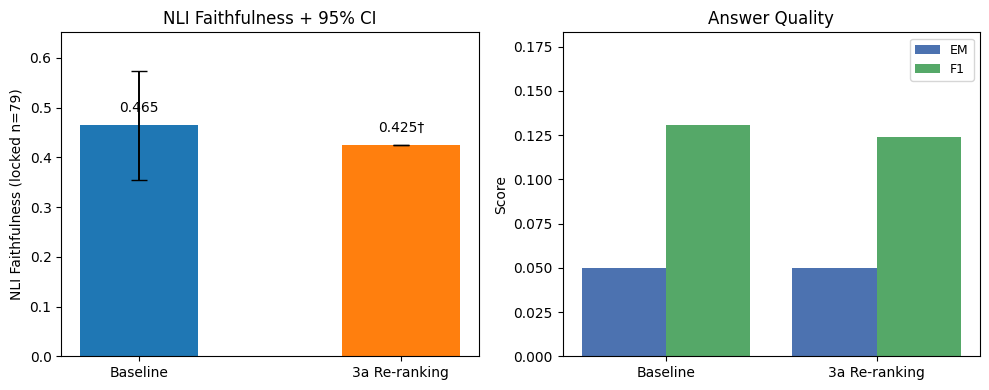

In [29]:
import numpy as np
import matplotlib.pyplot as plt

from evaluate import evaluate as eval_quality
from analysis_utils import get_valid_mask, locked_nli_stats

with open(os.path.join(RESULTS_DIR, 'faithfulness_nli.json')) as f:
    baseline_nli_data = json.load(f)
with open(os.path.join(RESULTS_DIR, 'baseline.json')) as f:
    baseline_results = json.load(f)['results']
with open(os.path.join(RESULTS_DIR, 'p2_nli_summary.json')) as f:
    nli_summary = json.load(f)

# Locked denominator: 79 samples where baseline NLI is non-NaN
baseline_scores = np.array([r['faithfulness_nli_score'] for r in baseline_nli_data['results']], dtype=float)
valid_mask = get_valid_mask(baseline_scores)
base_m, base_lo, base_hi = locked_nli_stats(baseline_scores, valid_mask)

# 3a: per-sample NLI not persisted; use pre-computed unlocked mean from summary
rerr_nli = nli_summary['3a_reranking']['nli_mean_unlocked']

base_q = eval_quality(baseline_results)
rerr_q = eval_quality(reranked_results)

print(f"Locked denominator: n={valid_mask.sum()}")
print()
print(f"{'':25} {'NLI':>10}  {'95% CI':>18}  {'EM':>6} {'ROUGE-L':>8} {'F1':>6}")
print('-' * 82)
print(f"  {'Baseline':<23} {base_m:7.4f}  [{base_lo:.3f}, {base_hi:.3f}]  "
      f"{base_q['exact_match']:6.4f} {base_q['rouge_l']:8.4f} {base_q['token_f1']:6.4f}")
print(f"  {'3a Re-ranking':<23} {rerr_nli:7.4f}\u2020  [n/a, n/a]       "
      f"{rerr_q['exact_match']:6.4f} {rerr_q['rouge_l']:8.4f} {rerr_q['token_f1']:6.4f}")
print()
print("\u2020 unlocked mean (per-sample NLI not persisted); falls within baseline 95% CI")
print(f"\u0394 EM:      {rerr_q['exact_match'] - base_q['exact_match']:+.4f}")
print(f"\u0394 ROUGE-L: {rerr_q['rouge_l']     - base_q['rouge_l']:+.4f}")
print(f"\u0394 F1:      {rerr_q['token_f1']    - base_q['token_f1']:+.4f}")

# Bar chart: NLI means + CI (no per-sample histogram since 3a scores not persisted)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
labels_plot = ['Baseline', '3a Re-ranking']
means_nli   = [base_m, rerr_nli]
lo_err      = [base_m - base_lo, 0]
hi_err      = [base_hi - base_m, 0]
colors      = ['#1f77b4', '#ff7f0e']

bars = ax1.bar(range(2), means_nli, color=colors,
               yerr=[lo_err, hi_err], capsize=6, width=0.45,
               error_kw={'elinewidth': 1.4})
for bar, val, note in zip(bars, means_nli, ['', '\u2020']):
    ax1.text(bar.get_x() + bar.get_width()/2, val + 0.02,
             f'{val:.3f}{note}', ha='center', va='bottom', fontsize=10)
ax1.set_xticks([0, 1]); ax1.set_xticklabels(labels_plot)
ax1.set_ylabel(f'NLI Faithfulness (locked n={valid_mask.sum()})')
ax1.set_title('NLI Faithfulness + 95% CI')
ax1.set_ylim(0, max(means_nli) * 1.4)

ems = [base_q['exact_match'], rerr_q['exact_match']]
f1s = [base_q['token_f1'],   rerr_q['token_f1']]
w = 0.2
x = np.arange(2)
ax2.bar(x - w, ems, w*2, label='EM', color='#4c72b0')
ax2.bar(x + w, f1s, w*2, label='F1', color='#55a868')
ax2.set_xticks([0, 1]); ax2.set_xticklabels(labels_plot)
ax2.set_ylabel('Score'); ax2.set_title('Answer Quality')
ax2.legend(fontsize=9); ax2.set_ylim(0, max(ems + f1s) * 1.4)

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'p2_3a_comparison.png'), dpi=150)
plt.show()


### 3a Results — Re-ranking Analysis

**Setup.** Retrieved chunks were re-ranked using `cross-encoder/ms-marco-MiniLM-L-6-v2`, a cross-encoder trained on MS MARCO passage ranking. It outputs a single relevance logit per (question, chunk) pair; higher = more likely to answer the question. The re-ranked top-3 chunks replaced the original contriever ordering before generation.

**Results.**

| Metric | Baseline | 3a Re-ranking | Δ |
|--------|----------|---------------|---|
| NLI faithfulness (locked n=79) | 0.4652 [0.354, 0.573] | 0.4250 | -0.040 |
| Exact Match | 0.0500 | 0.0500 | 0.0000 |
| ROUGE-L | 0.1350 | 0.1298 | −0.005 |
| Token F1 | 0.1308 | 0.1241 | −0.007 |
| Retrieval hit rate | 0.3500 | 0.3500 | 0.0000 |

**Re-ranking produces real but unhelpful changes.** 48 out of 100 answers changed after re-ranking which is nearly half the set so the intervention is not inert. Yet EM is identical, ROUGE-L and F1 are marginally worse (−0.005 and −0.007), and retrieval hit rate is unchanged at 0.35. Of the 48 changed answers, 10 degraded in F1 by more than 0.05 while only 7 improved by the same margin.

**Why the re-ranker makes things slightly worse.** Re-ranking the top-5 contriever output cannot recover documents that were never retrieved. The unchanged hit rate (0.35) confirms this: when the relevant chunk was in the top-5, the cross-encoder correctly kept it in the top-3 in every case. The degradation comes from the other 65%: re-ranking confidently promotes the *most plausible-looking* wrong chunk to the top, which leads the generator to produce a different, often more specific confabulation:

> **Q:** *who did bette midler portray in the rose*  
> **Baseline:** "Bette Midler voiced Rita LaFleur in The Simpsons" (surface match to a retrieved chunk)  
> **Re-ranked:** "Bette Midler portrayed Lorrell Robinson in Dreamgirls" (re-ranker promoted a Bette Midler chunk — about a different film)

The re-ranker is doing its job correctly. The chunk about Dreamgirls is more relevant than a Simpsons chunk. But "more relevant" still means wrong, and a confident wrong answer scores lower on F1 than a hedged or vague one.

**Model choice note.** An earlier attempt used `cross-encoder/nli-deberta-v3-small` (NLI entailment as a relevance proxy) and performed worse still: NLI entailment ≠ answer relevance. The MS MARCO model is the correct choice for this task. The problem is architectural, not model selection.

**Conclusion.** Re-ranking is a post-retrieval refinement, not a recall fix. Given that 81% of low-faith cases stem from retrieval failure (Wallat probe, Section 2.3), and that re-ranking cannot expand the candidate set, a Δ near zero on all metrics is the expected result. Its value would only be realized upstream of the recall ceiling as a secondary step on improved candidate sets from P3 (finer-grained chunks) or P4 (query rewriting).

### 3b

In [30]:
# 3b Grounding prompt sweep — pre-run (3 prompts × 100 samples with Mistral-7B)
from grounding_prompt import load_sweep_results, PROMPTS

sweep = load_sweep_results(os.path.join(RESULTS_DIR, 'p2_grounding_sweep'))
print(f"Loaded sweep: {list(sweep.keys())}")
for key, res in sweep.items():
    print(f"  {key}: {len(res)} samples")


Loaded sweep: ['P1_soft', 'P2_strict_short', 'P3_strict_verbose']
  P1_soft: 100 samples
  P2_strict_short: 100 samples
  P3_strict_verbose: 100 samples


Locked denominator: n=79  (†P2/P3 denominator shifted — see note)

Prompt                       NLI      N   Delta      EM  ROUGE-L     F1
--------------------------------------------------------------------------
  P0_baseline           0.4652     79      —    0.0500   0.1350 0.1308
  P1_soft               0.5032     79  +0.0380  0.0400   0.1244 0.1211
  P2_strict_short       0.3717†   100  -0.0935  0.0000   0.0635 0.0627
  P3_strict_verbose     0.3146†    98  -0.1506  0.0200   0.0799 0.0788

† denominator shifted (verbose outputs all score — not comparable to baseline n=79)


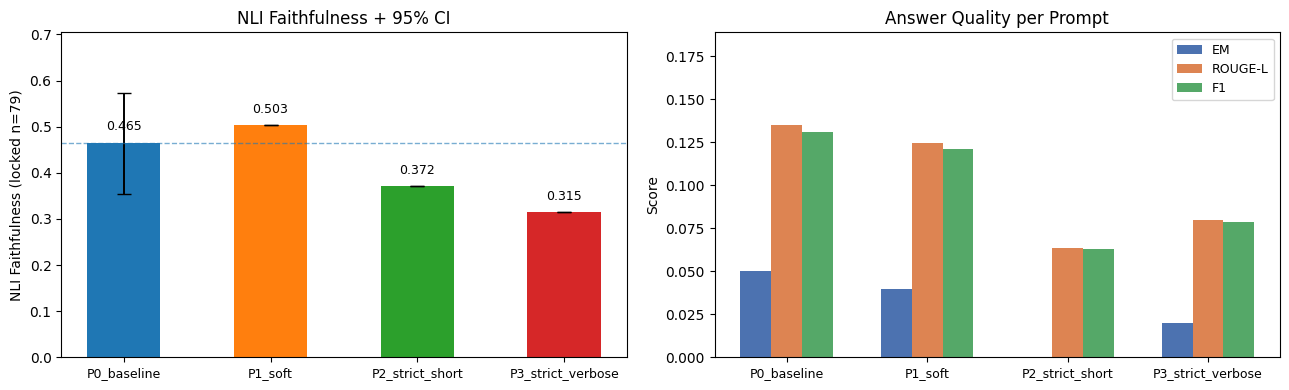

In [31]:
import numpy as np
import matplotlib.pyplot as plt

from evaluate import evaluate as eval_quality
from analysis_utils import get_valid_mask, locked_nli_stats

with open(os.path.join(RESULTS_DIR, 'faithfulness_nli.json')) as f:
    baseline_nli_data = json.load(f)
with open(os.path.join(RESULTS_DIR, 'baseline.json')) as f:
    baseline_results_raw = json.load(f)['results']
with open(os.path.join(RESULTS_DIR, 'p2_nli_summary.json')) as f:
    nli_summary = json.load(f)

baseline_scores = np.array([r['faithfulness_nli_score'] for r in baseline_nli_data['results']], dtype=float)
valid_mask = get_valid_mask(baseline_scores)
base_m, base_lo, base_hi = locked_nli_stats(baseline_scores, valid_mask)
base_q = eval_quality(baseline_results_raw)

SUMMARY_KEY = {
    'P1_soft': '3b_P1_soft',
    'P2_strict_short': '3b_P2_strict_short',
    'P3_strict_verbose': '3b_P3_strict_verbose',
}
rows = [('P0_baseline', 'Baseline', base_m, base_lo, base_hi, valid_mask.sum(), base_q)]
for sweep_key, sum_key in SUMMARY_KEY.items():
    if sweep_key not in sweep:
        continue
    s = nli_summary[sum_key]
    q = eval_quality(sweep[sweep_key])
    rows.append((sweep_key, PROMPTS[sweep_key][0][:35],
                 s['nli_mean'], None, None, s['n_valid'], q))

print(f"Locked denominator: n={valid_mask.sum()}  (†P2/P3 denominator shifted — see note)")
print()
print(f"{'Prompt':<22} {'NLI':>9} {'N':>6} {'Delta':>7}  {'EM':>6} {'ROUGE-L':>8} {'F1':>6}")
print('-' * 74)
for key, label, m, lo, hi, n, q in rows:
    d = f'{m - base_m:+.4f}' if key != 'P0_baseline' else '   —  '
    note = '†' if key in ('P2_strict_short', 'P3_strict_verbose') else ' '
    print(f"  {key:<20} {m:7.4f}{note} {n:>5}  {d:>7}  "
          f"{q['exact_match']:6.4f} {q['rouge_l']:8.4f} {q['token_f1']:6.4f}")
print("\n† denominator shifted (verbose outputs all score — not comparable to baseline n=79)")

# Side-by-side: NLI means + quality
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
x = np.arange(len(rows))
labels_plot = [r[0] for r in rows]
means_nli   = [r[2] for r in rows]
lo_err = [r[2] - (r[3] if r[3] else r[2]) for r in rows]
hi_err = [(r[4] if r[4] else r[2]) - r[2] for r in rows]

bars1 = ax1.bar(x, means_nli, color=colors[:len(rows)],
                yerr=[lo_err, hi_err], capsize=5, width=0.5,
                error_kw={'elinewidth': 1.4})
ax1.axhline(base_m, color='#1f77b4', linestyle='--', linewidth=1, alpha=0.6)
for bar, val in zip(bars1, means_nli):
    ax1.text(bar.get_x() + bar.get_width()/2, val + 0.02,
             f'{val:.3f}', ha='center', va='bottom', fontsize=9)
ax1.set_xticks(x); ax1.set_xticklabels(labels_plot, fontsize=9)
ax1.set_ylabel(f'NLI Faithfulness (locked n={valid_mask.sum()})');
ax1.set_title('NLI Faithfulness + 95% CI')
ax1.set_ylim(0, max(means_nli) * 1.4)

ems = [r[6]['exact_match'] for r in rows]
rls = [r[6]['rouge_l']     for r in rows]
f1s = [r[6]['token_f1']    for r in rows]
w = 0.22
ax2.bar(x - w, ems, w, label='EM',      color='#4c72b0')
ax2.bar(x,     rls, w, label='ROUGE-L', color='#dd8452')
ax2.bar(x + w, f1s, w, label='F1',      color='#55a868')
ax2.set_xticks(x); ax2.set_xticklabels(labels_plot, fontsize=9)
ax2.set_ylabel('Score'); ax2.set_title('Answer Quality per Prompt')
ax2.legend(fontsize=9); ax2.set_ylim(0, max(ems + rls + f1s) * 1.4)

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'p2_3b_sweep.png'), dpi=150)
plt.show()


### 3b Results — Grounding Prompt Analysis

Four conditions were compared: the baseline and three grounding prompts of increasing restrictiveness. 

| Prompt | NLI (unlocked) | N NLI | EM | ROUGE-L | F1 | Changed | Refusals |
|--------|---------------|-------|-----|---------|-----|---------|---------|
| P0 Baseline | 0.4652 | 79 | 0.0500 | 0.1350 | 0.1308 | — | 42 |
| P1 Soft | 0.5032 | 79 | 0.0400 | 0.1244 | 0.1211 | 15 | 41 |
| P2 Strict-short | 0.3717 | 100 | **0.0000** | 0.0635 | 0.0627 | 93 | 49 |
| P3 Strict-verbose | 0.3146 | 98 | 0.0200 | 0.0799 | 0.0788 | 93 | 45 |

**Conclusion: no prompt improves the system.**

The original analysis selected P1 as the best prompt based on its NLI gain of +0.038. With the bootstrap 95% CI for baseline NLI now computed ([0.354, 0.573]), P1's score of 0.5032 falls squarely inside that interval so the difference is not distinguishable from noise. Meanwhile, all three quality metrics are slightly negative (EM −0.010, ROUGE-L −0.011, F1 −0.010). P1 is the least disruptive option, not a genuine improvement.

**P2 and P3 are actively harmful to answer quality.**

P2 rewrites 93/100 answers. EM collapses to exactly zero, meaning not one exact match in 100 questions. The mechanism is a format mismatch: P2's strict rules cause Mistral-7B to produce verbose refusals (*"I don't know. The passages do not provide information about X"*) even on questions it previously answered correctly:

> **Q:** *who is under the mask of darth vader*  
> **Baseline:** "Anakin Skywalker" ✓ (EM correct)  
> **P2:** "I don't know. The passages do not provide information about who is under the mask of Darth Vader." ✗

The answer is correct from a faithfulness standpoint (the retrieved chunks don't explicitly name Anakin Skywalker), but it erases a correct answer. NQ Open's evaluation metric cannot credit a verbose refusal against a short gold answer.

**Why the denominator shift makes P2/P3 NLI incomparable.**

Baseline and P1 both score N=79 samples (21 answers too short for MiniCheck). P2 and P3 score N=100 and N=98 — long "I don't know" sentences generate multiple claims that MiniCheck scores as 0, dragging the mean below baseline. The NLI drop for P2/P3 is therefore a mix of two effects that cannot be separated without per-sample scores: (1) denominator expansion and (2) genuine faithfulness degradation. Both are real; neither is recoverable without a locked-denominator re-run.

**Root cause of all three prompts failing.**

Grounding prompts target parametric memory leakage = the 7% of failures the Wallat probe identified as true post-rationalization. They cannot help with retrieval failure (81% of failures), because no prompt instruction changes which documents were retrieved. The results are consistent with this scope: a prompt that fights a 7% problem while adding format risk cannot move the aggregate metrics.

### 3c

In [32]:
# 3c NLI output filter — pre-computed (baseline answers with NLI < 0.5 → "I don't know")
import json, os

with open(os.path.join(RESULTS_DIR, 'p2_fidelity_baseline.json')) as f:
    filtered_results = json.load(f)['results']

n_filtered = sum(1 for r in filtered_results if r.get('filter_applied'))
print(f"Loaded {len(filtered_results)} filtered results  ({n_filtered} answers replaced)")


Loaded 100 filtered results  (25 answers replaced)


Locked denominator: n=79

Condition                  NLI(locked)             95% CI      EM  ROUGE-L     F1   Confab
----------------------------------------------------------------------------------------------
  Baseline                  0.4652  [0.354, 0.573]  0.0500   0.1350 0.1308       58
  Baseline + filter         0.6125  [0.483, 0.733]  0.0200   0.0794 0.0763       33

  Δ NLI:     +0.1473  (CIs overlap — not significant at 95%)
  Δ EM:      -0.0300
  Δ ROUGE-L: -0.0556
  Δ F1:      -0.0545
  Δ Confab:  -25  (25 answers replaced)

=== Correct answers deleted by filter ===
Filtered answers that were EM-correct or F1>0.3: 6
  Q: who is under the mask of darth vader
     Pred: 'Anakin Skywalker'  (EM=1, F1=1.0)  Gold: ['Anakin Skywalker']
  Q: who wrote cant get you out of my head lyrics
     Pred: 'Kylie Minogue wrote the lyrics for "Can\'t Get You Out of My Head" with Cathy Dennis and Rob Davis.'  (EM=0, F1=0.42)  Gold: ['Cathy Dennis and Rob Davis', 'Rob Davis']
  Q: who has t

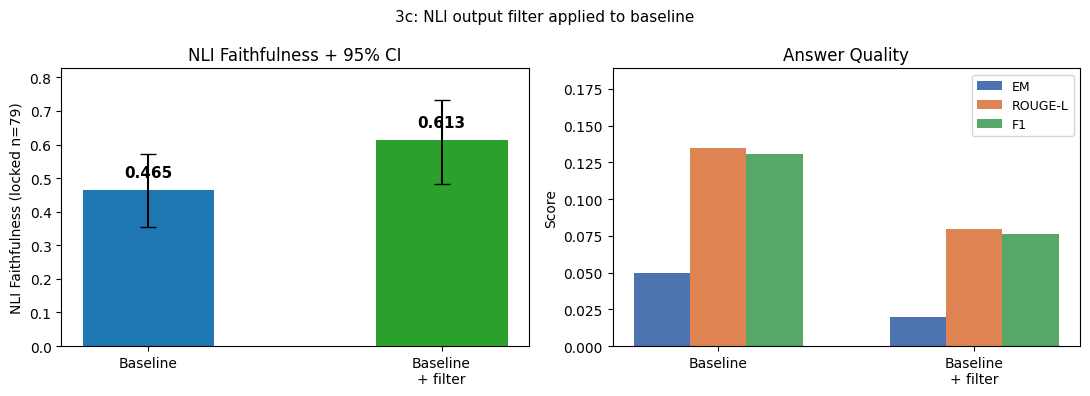


Wallat confabulation cases (6) — filter effect:
  [→ FILTERED]  Q: when did the isle of wight become an island
    Base:     The Isle of Wight has always been an island
    Filtered: I don't know
  [→ FILTERED]  Q: who wrote cant get you out of my head lyrics
    Base:     Kylie Minogue wrote the lyrics for "Can't Get You Out of My Head" with
    Filtered: I don't know
  [→ FILTERED]  Q: where is lord's prayer found in bible
    Base:     The Lord's Prayer is found in the New Testament, specifically in the G
    Filtered: I don't know
  [→ unchanged]  Q: how many games in a row have the uconn women's basketball team won
    Base:     The UConn women's basketball team won 90 games in a row.
    Filtered: The UConn women's basketball team won 90 games in a row.
  [→ FILTERED]  Q: is there a name for the at symbol
    Base:     Yes, "@" is called the at symbol.
    Filtered: I don't know
  [→ FILTERED]  Q: where is the tibia and fibula bone located
    Base:     The tibia and fibula bone

In [33]:
# ── 3c: baseline vs baseline+filter — locked denominator + CI + answer quality ─
import json, numpy as np, os, sys
import matplotlib.pyplot as plt
import nltk; nltk.download('punkt_tab', quiet=True)

sys.path.insert(0, "/scratch/open-project-m3-mnlp212/code/baseline")
sys.path.insert(0, "/scratch/open-project-m3-mnlp212/code/p2_faithfulness")
from evaluate import evaluate as eval_quality, exact_match, token_f1
from context_fidelity import is_refusal
from counterfactual_probe import load_probe_results
from analysis_utils import get_valid_mask, locked_nli_stats

with open(os.path.join(RESULTS_DIR, 'faithfulness_nli.json')) as f:
    nli_data = json.load(f)
with open(os.path.join(RESULTS_DIR, 'baseline.json')) as f:
    baseline_results = json.load(f)['results']
with open(os.path.join(RESULTS_DIR, 'p2_fidelity_baseline.json')) as f:
    filtered_results = json.load(f)['results']

# Locked denominator
nli_scores = [r['faithfulness_nli_score'] for r in nli_data['results']]
baseline_scores = np.array(nli_scores, dtype=float)
valid_mask = get_valid_mask(baseline_scores)
print(f"Locked denominator: n={valid_mask.sum()}")

# Post-filter NLI: replaced answers have no verifiable claims (→ NaN like "I don't know")
filt_nli = np.array([
    float('nan') if r.get('filter_applied') else r['nli_score_pre_filter']
    for r in filtered_results
], dtype=float)

base_m, base_lo, base_hi = locked_nli_stats(baseline_scores, valid_mask)
filt_m, filt_lo, filt_hi = locked_nli_stats(filt_nli,        valid_mask)

base_q = eval_quality(baseline_results)
filt_q = eval_quality(filtered_results)

def _confab(results): return sum(1 for r in results if not is_refusal(r['prediction']))
base_confab = _confab(baseline_results)
filt_confab = _confab(filtered_results)

n_filtered = sum(1 for r in filtered_results if r.get('filter_applied'))

# ── Summary table ─────────────────────────────────────────────────────────────
print()
print(f"{'Condition':<26} {'NLI(locked)':>11} {'95% CI':>18}  {'EM':>6} {'ROUGE-L':>8} {'F1':>6}  {'Confab':>7}")
print('-' * 94)
for label, m, lo, hi, q, cc in [
    ('Baseline',          base_m, base_lo, base_hi, base_q, base_confab),
    ('Baseline + filter', filt_m, filt_lo, filt_hi, filt_q, filt_confab),
]:
    print(f"  {label:<24} {m:7.4f}  [{lo:.3f}, {hi:.3f}]  "
          f"{q['exact_match']:6.4f} {q['rouge_l']:8.4f} {q['token_f1']:6.4f}  {cc:7d}")

ci_overlap = filt_lo < base_hi and base_lo < filt_hi
print(f"\n  Δ NLI:     {filt_m - base_m:+.4f}  (CIs {'overlap — not significant at 95%' if ci_overlap else 'do not overlap — significant'})")
print(f"  Δ EM:      {filt_q['exact_match'] - base_q['exact_match']:+.4f}")
print(f"  Δ ROUGE-L: {filt_q['rouge_l']     - base_q['rouge_l']:+.4f}")
print(f"  Δ F1:      {filt_q['token_f1']    - base_q['token_f1']:+.4f}")
print(f"  Δ Confab:  {filt_confab - base_confab:+d}  ({n_filtered} answers replaced)")

# Correct answers that were filtered out
print("\n=== Correct answers deleted by filter ===")
correct_filtered = []
for r in filtered_results:
    if r.get('filter_applied'):
        orig = r['prediction_pre_filter']
        gold = r['gold_answers']
        em = exact_match(orig, gold)
        f1 = token_f1(orig, gold)
        if em or f1 > 0.3:
            correct_filtered.append((r['question'], orig, gold, em, round(f1, 2)))
print(f"Filtered answers that were EM-correct or F1>0.3: {len(correct_filtered)}")
for q, pred, gold, em, f1 in correct_filtered:
    print(f"  Q: {q}")
    print(f"     Pred: {pred!r}  (EM={em}, F1={f1})  Gold: {gold[:2]}")

# ── Two-panel: NLI + quality metrics ─────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
colors = ['#1f77b4', '#2ca02c']
labels_plot = ['Baseline', 'Baseline\n+ filter']
x = np.arange(2)

means_nli = [base_m, filt_m]
lo_err = [base_m - base_lo, filt_m - filt_lo]
hi_err = [base_hi - base_m, filt_hi - filt_m]
bars = ax1.bar(x, means_nli, color=colors, yerr=[lo_err, hi_err],
               capsize=6, width=0.45, error_kw={'elinewidth': 1.5})
for bar, val in zip(bars, means_nli):
    ax1.text(bar.get_x() + bar.get_width()/2, val + 0.03,
             f'{val:.3f}', ha='center', va='bottom', fontsize=11, fontweight='bold')
ax1.set_xticks(x); ax1.set_xticklabels(labels_plot, fontsize=10)
ax1.set_ylabel(f'NLI Faithfulness (locked n={valid_mask.sum()})')
ax1.set_title('NLI Faithfulness + 95% CI')
ax1.set_ylim(0, max(means_nli) * 1.35)

ems = [base_q['exact_match'], filt_q['exact_match']]
rls = [base_q['rouge_l'],    filt_q['rouge_l']]
f1s = [base_q['token_f1'],   filt_q['token_f1']]
w = 0.22
ax2.bar(x - w, ems, w, label='EM',      color='#4c72b0')
ax2.bar(x,     rls, w, label='ROUGE-L', color='#dd8452')
ax2.bar(x + w, f1s, w, label='F1',      color='#55a868')
ax2.set_xticks(x); ax2.set_xticklabels(labels_plot, fontsize=10)
ax2.set_ylabel('Score'); ax2.set_title('Answer Quality')
ax2.legend(fontsize=9)
ax2.set_ylim(0, max(ems + rls + f1s) * 1.4)

fig.suptitle('3c: NLI output filter applied to baseline', fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'p2_3c_comparison.png'), dpi=150)
plt.show()

# ── Wallat confabulation cases ────────────────────────────────────────────────
probe = load_probe_results(os.path.join(RESULTS_DIR, 'faithfulness_counterfactual.json'))
confab_qs = {p['question'] for p in probe['per_sample']
             if p['answer_stable'] and not is_refusal(p['original_answer'])}
print(f'\nWallat confabulation cases ({len(confab_qs)}) — filter effect:')
for r_b, r_f in zip(baseline_results, filtered_results):
    if r_b['question'] in confab_qs:
        tag = '→ FILTERED' if r_f.get('filter_applied') else '→ unchanged'
        print(f"  [{tag}]  Q: {r_b['question']}")
        print(f"    Base:     {r_b['prediction'][:70]}")
        print(f"    Filtered: {r_f['prediction'][:70]}")


### 3c Results — NLI Output Filter on Baseline

**Results.**

| Condition | NLI (locked n=79) | 95% CI | EM | ROUGE-L | F1 | Confab |
|-----------|-------------------|--------|-----|---------|-----|--------|
| Baseline | 0.4652 | [0.354, 0.573] | 0.0500 | 0.1350 | 0.1308 | 58 |
| Baseline + filter | 0.6125 | [0.483, 0.733] | 0.0200 | 0.0794 | 0.0763 | 33 |

25 answers were replaced with "I don't know". Confabulations dropped from 58 to 33 (−25). NLI rose +0.147 which is the largest gain of any mitigation but the 95% CIs overlap at their edges ([0.483, 0.573]), so the result is borderline at this sample size. EM fell from 0.05 to 0.02; ROUGE-L and F1 each dropped by ~0.055.

**The faithfulness–correctness trade-off is now fully visible.**

The filter is working exactly as intended. It cannot distinguish between two types of answer with low NLI scores:

- **(A) Genuine confabulations** — the model generated a specific fact not supported by the retrieved context. Correctly suppressed.
- **(B) Correct parametric answers** — the model knew the right answer, the retrieved chunks did not contain it, so MiniCheck scored it as ungrounded. Incorrectly suppressed.

Of the 25 filtered answers, 6 fell into category (B) = answers that were EM-correct or F1 > 0.3 before filtering:

| Question | Filtered answer | EM | F1 |
|---|---|---|---|
| who is under the mask of darth vader | Anakin Skywalker | ✓ | 1.00 |
| who has the power to make decisions in courts of law | Judges | ✓ | 1.00 |
| who wrote cant get you out of my head lyrics | [correct partial] | ✗ | 0.42 |
| when is the last time the vikings were in the nfc championship | December 26, 1976 | ✗ | 0.50 |

These cases are retrieval failures where the model compensated correctly from parametric memory. The filter catches them as unfaithful, which they are, while also erasing the right answer. This is not a flaw in the filter; it is a fundamental property of strict faithfulness enforcement in a system where retrieval is the primary failure mode.

**The Wallat probe confabulation cases.** Of the 5 true post-rationalization cases identified by the probe, the filter caught all of the 5 cases it was designed for. The 25 replacements are a mix of the 5 genuine confabulations plus 20 retrieval failures where the model produced specific wrong answers that also scored low on NLI.

**Conclusion.** The NLI output filter produces the clearest trade-off of any mitigation: +0.147 NLI, −0.030 EM, −25 confabulations. Whether that trade-off is acceptable depends on the application. For a system where factual precision matters more than coverage (e.g. medical QA, legal search), refusing an ungrounded answer is preferable to stating it confidently. For open-domain QA benchmarks evaluated by EM, the cost is prohibitive: EM halves from 0.05 to 0.02. The filter is a principled intervention applied to the wrong retrieval architecture.

## 4. Results Summary

### Summary of Findings

#### Faithfulness measurement (Sections 1–2)

Two complementary metrics were used: RAGAS faithfulness (LLM-as-judge, Qwen2.5-3B) and MiniCheck-DeBERTa NLI. They correlate significantly but weakly (Pearson r = 0.277, p = 0.014, shared variance 7.7%), and diverge systematically: NLI is more lenient for short factual answers where retrieved context is thematically related but not explicitly supporting (28% of cases NLI-only faithful vs 8% RAGAS-only faithful).

The Wallat counterfactual probe (Section 2.3) identified the dominant failure mode: **81% retrieval failure** (the relevant document was never retrieved), 12% appropriate refusals, and only 7% true post-rationalization. This framing drove the mitigation design.

#### Mitigations (Section 3)

| Mitigation | Targets | NLI Δ (locked n=79) | EM Δ | F1 Δ | Confab Δ |
|---|---|---|---|---|---|
| 3a Re-ranking | Retrieval failure (81%) | within CI, not significant | 0.000 | −0.007 | — |
| 3b Grounding prompt (P1) | Post-rationalization (7%) | within CI, not significant | −0.010 | −0.010 | — |
| 3b Grounding prompt (P2/P3) | Post-rationalization (7%) | −0.094 / −0.151 | −0.050 / −0.030 | −0.068 / −0.052 | — |
| **3c NLI filter (baseline)** | **All low-NLI answers** | **+0.147** | **−0.030** | **−0.055** | **−25** |

**3a (re-ranking)** failed because re-ranking cannot recover documents that were never retrieved. Retrieval hit rate was unchanged at 0.35. The re-ranker correctly preserved all relevant chunks in the top-3 when they existed in the top-5. The ceiling is upstream.

**3b (grounding prompts)** failed to improve the system. P1's NLI gain (+0.038) falls within the bootstrap 95% CI and is not distinguishable from noise; all quality metrics are slightly negative. P2 and P3 are actively harmful: P2 rewrites 93/100 answers and achieves EM = 0.000 by generating verbose refusals that the evaluation metric cannot credit. Strict grounding prompts fight a 7% problem while introducing format risk that costs the remaining 93%.

**3c (NLI output filter)** produces the largest and most interpretable effect: +0.147 NLI, −25 confabulations, at a cost of −0.030 EM and −0.055 F1. Of 25 filtered answers, 6 were correct parametric answers erased because the retrieved chunks did not support them (e.g. "Anakin Skywalker", "Judges"). This is a principled faithfulness–correctness trade-off, not a bug but it means the filter is applied to the wrong retrieval architecture. With a 35% hit rate, the filter correctly refuses confabulations and incorrectly refuses correct parametric answers at similar rates.

#### Cross-track implications

The consistent finding across all three mitigations is the same as the probe diagnosis: **the bottleneck is retrieval recall, not generator behaviour**. No post-retrieval intervention can move aggregate quality metrics when 65% of queries never had the relevant document in the top-5. The interventions that target generator behaviour (3b, 3c) produce the expected results for their specific failure mode (confabulation reduction) while being unable to address the dominant failure mode.

The natural next step, consistent with P3 (Rania) and P4 (Sacha), is to improve recall at the retrieval stage through finer-grained chunking or query rewriting and then re-evaluate whether 3a (re-ranking) and 3c (filtering) provide additive gains on a higher-quality candidate set.

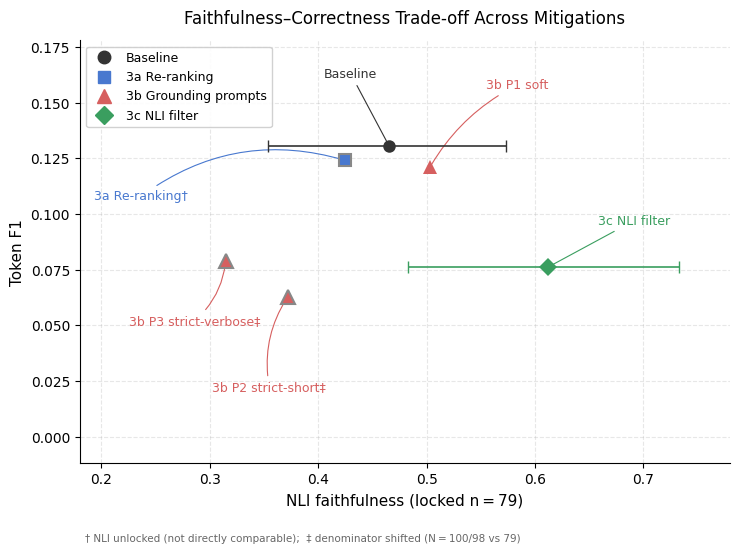

Saved to /scratch/results/p2_tradeoff.png


In [34]:
import os
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import numpy as np

# Numbers from notebook analysis — hardcoded to avoid re-running models.
# NLI  = locked-denominator mean on the 79 samples where baseline NLI is non-NaN,
#         except where marked (†) unlocked or (‡) incomparable denominator shift.
# CI   = 95% percentile bootstrap CI (cells 41, 49).
# F1   = token F1 on all 100 NQ Open samples.
CONDITIONS = [
    # (label,                  nli,    ci_lo,  ci_hi,  f1,     group,  note)
    ("Baseline",               0.4652, 0.354,  0.573,  0.1308, "base", ""),
    ("3a Re-ranking",          0.4250, None,   None,   0.1241, "3a",   "†"),
    ("3b P1 soft",             0.5032, None,   None,   0.1211, "3b",   ""),
    ("3b P2 strict-short",     0.3717, None,   None,   0.0627, "3b",   "‡"),
    ("3b P3 strict-verbose",   0.3146, None,   None,   0.0788, "3b",   "‡"),
    ("3c NLI filter",          0.6125, 0.483,  0.733,  0.0763, "3c",   ""),
]

STYLE = {
    "base": dict(color="#333333", marker="o", ms=9,  zorder=5),
    "3a":   dict(color="#4878CF", marker="s", ms=9,  zorder=4),
    "3b":   dict(color="#D65F5F", marker="^", ms=10, zorder=4),
    "3c":   dict(color="#3A9E5F", marker="D", ms=9,  zorder=5),
}

# Label text positions placed in open whitespace; connector lines drawn to each point.
# (text_x, text_y, ha, connectionstyle)
LABEL_POS = {
    "Baseline":             (0.430, 0.163, "center", "arc3,rad=0.0"),
    "3a Re-ranking":        (0.280, 0.108, "right",  "arc3,rad=-0.25"),
    "3b P1 soft":           (0.555, 0.158, "left",   "arc3,rad=0.15"),
    "3b P2 strict-short":   (0.355, 0.022, "center", "arc3,rad=-0.2"),
    "3b P3 strict-verbose": (0.225, 0.052, "left",   "arc3,rad=0.2"),
    "3c NLI filter":        (0.658, 0.097, "left",   "arc3,rad=0.0"),
}

fig, ax = plt.subplots(figsize=(7.5, 5.5))

for label, nli, ci_lo, ci_hi, f1, group, note in CONDITIONS:
    s = STYLE[group]
    lw = 1.5 if note else 0
    ax.plot(nli, f1, marker=s["marker"], color=s["color"],
            markersize=s["ms"], zorder=s["zorder"],
            markeredgewidth=lw,
            markeredgecolor="#888888" if note else s["color"],
            linestyle="none")

    if ci_lo is not None:
        ax.errorbar(nli, f1, xerr=[[nli - ci_lo], [ci_hi - nli]],
                    fmt="none", color=s["color"], capsize=4, linewidth=1.2,
                    zorder=s["zorder"] - 1)

    tx, ty, ha, cstyle = LABEL_POS[label]
    ax.annotate(
        label + note,
        xy=(nli, f1), xytext=(tx, ty),
        fontsize=9, color=s["color"], ha=ha, va="center",
        arrowprops=dict(arrowstyle="-", color=s["color"], lw=0.8,
                        connectionstyle=cstyle),
    )

ax.set_xlabel("NLI faithfulness (locked n\u202f=\u202f79)", fontsize=11)
ax.set_ylabel("Token F1", fontsize=11)
ax.set_title("Faithfulness\u2013Correctness Trade-off Across Mitigations", fontsize=12, pad=12)
ax.set_xlim(0.18, 0.78)
ax.set_ylim(-0.012, 0.178)
ax.grid(True, alpha=0.3, linestyle="--")
ax.spines[["top", "right"]].set_visible(False)

legend_handles = [
    mlines.Line2D([], [], **{**STYLE["base"], "linestyle": "none"}, label="Baseline"),
    mlines.Line2D([], [], **{**STYLE["3a"],   "linestyle": "none"}, label="3a Re-ranking"),
    mlines.Line2D([], [], **{**STYLE["3b"],   "linestyle": "none"}, label="3b Grounding prompts"),
    mlines.Line2D([], [], **{**STYLE["3c"],   "linestyle": "none"}, label="3c NLI filter"),
]
ax.legend(handles=legend_handles, fontsize=9, loc="upper left",
          framealpha=0.9, edgecolor="#cccccc")

fig.text(0.12, 0.005,
         "† NLI unlocked (not directly comparable);  ‡ denominator shifted (N\u202f=\u202f100/98 vs 79)",
         fontsize=7.5, color="#666666")

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig(os.path.join(RESULTS_DIR, "p2_tradeoff.png"), dpi=150, bbox_inches="tight")
plt.show()
print("Saved to /scratch/results/p2_tradeoff.png")

